## 任务分发

In [1]:
from typing import Annotated, TypedDict
from operator import add
from langgraph.graph import StateGraph, START
from langgraph.constants import END
from langgraph.types import Send


class State(TypedDict):
    tasks: list[str]  # 原始任务列表
    results: Annotated[list[str], add]  # 自动累加各通道结果
    summary: str  # 最终汇总文本

In [2]:
def distribute(state: State):
    # 含"急" -> 快速通道, 含"深度" -> 深度通道, 其他 -> 常规通道
    sends = []
    for task in state["tasks"]:
        if "急" in task:
            sends.append(Send("process_fast", {"task": task}))
        elif "深度" in task:
            sends.append(Send("process_deep", {"task": task}))
        else:
            sends.append(Send("process_default", {"task": task}))
    return sends


def process_fast(state: State) -> State:
    print("process_fast:", state["task"])
    return {"results": ["✅ 完成: " + state["task"]]}


def process_deep(state: State) -> State:
    print("process_deep:", state["task"])
    return {"results": ["🔍 完成: " + state["task"]]}


def process_default(state: State) -> State:
    print("process_default:", state["task"])
    return {"results": ["📦 完成: " + state["task"]]}

In [3]:
def summarize(state: State) -> State:
    results = state["results"]
    fast = sum(1 for r in results if r.startswith("✅"))
    deep = sum(1 for r in results if r.startswith("🔍"))
    default = sum(1 for r in results if r.startswith("📦"))
    summary = "工单处理汇总\n总计完成: {} 个任务\n快速通道 ✅: {} | 深度通道 🔍: {} | 常规通道 📦: {}".format(
        len(results), fast, deep, default)
    print("summarize: 汇总完成")
    return {"summary": summary}

In [4]:
builder = StateGraph(State)
builder.add_node("process_fast", process_fast)
builder.add_node("process_deep", process_deep)
builder.add_node("process_default", process_default)
builder.add_node("summarize", summarize, defer=True)

In [5]:
builder.add_conditional_edges(
    START, distribute, ["process_fast", "process_deep", "process_default"])
builder.add_edge("process_fast", "summarize")
builder.add_edge("process_deep", "summarize")
builder.add_edge("process_default", "summarize")
builder.add_edge("summarize", END)

graph = builder.compile()

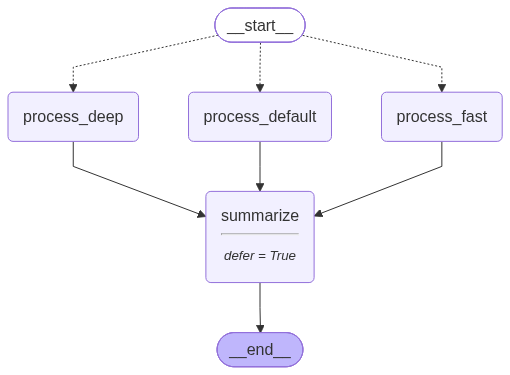

In [6]:
graph

## 测试验证

In [7]:
initial = {
    "tasks": [
        "急：修复线上支付故障",
        "深度分析上季度用户留存数据",
        "整理本周会议纪要",
        "紧急补发客户发票",
        "常规更新产品文档",
    ],
    "results": [],
    "summary": "",
}

In [8]:
for chunk in graph.stream(initial):
    print(chunk)

process_fast: 急：修复线上支付故障
process_deep: 深度分析上季度用户留存数据
process_default: 整理本周会议纪要
process_fast: 紧急补发客户发票
process_default: 常规更新产品文档
{'process_fast': {'results': ['✅ 完成: 急：修复线上支付故障']}}
{'process_deep': {'results': ['🔍 完成: 深度分析上季度用户留存数据']}}
{'process_default': {'results': ['📦 完成: 整理本周会议纪要']}}
{'process_fast': {'results': ['✅ 完成: 紧急补发客户发票']}}
{'process_default': {'results': ['📦 完成: 常规更新产品文档']}}
summarize: 汇总完成
{'summarize': {'summary': '工单处理汇总\n总计完成: 5 个任务\n快速通道 ✅: 2 | 深度通道 🔍: 1 | 常规通道 📦: 2'}}


In [9]:
res = graph.invoke(initial)

process_fast: 急：修复线上支付故障
process_deep: 深度分析上季度用户留存数据
process_default: 整理本周会议纪要
process_fast: 紧急补发客户发票
process_default: 常规更新产品文档
summarize: 汇总完成


In [10]:
res

{'tasks': ['急：修复线上支付故障', '深度分析上季度用户留存数据', '整理本周会议纪要', '紧急补发客户发票', '常规更新产品文档'],
 'results': ['✅ 完成: 急：修复线上支付故障',
  '🔍 完成: 深度分析上季度用户留存数据',
  '📦 完成: 整理本周会议纪要',
  '✅ 完成: 紧急补发客户发票',
  '📦 完成: 常规更新产品文档'],
 'summary': '工单处理汇总\n总计完成: 5 个任务\n快速通道 ✅: 2 | 深度通道 🔍: 1 | 常规通道 📦: 2'}